<a href="https://colab.research.google.com/github/Sakshilonkar-hub/VOLTRELAY-ENERGY/blob/main/Copy_of_VoltRelay_Full_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

 VoltRelay Energy: Battery-Swap Network Analysis
 **Gradient Learnings Data Analytics Hackathon**

 ## Problem Statement
  VoltRelay Energy runs a battery-swapping network for electric two-wheelers (2W) and three-wheelers (3W) across six Indian cities: Bengaluru, Delhi NCR, Hyderabad, Pune, Mumbai, and Jaipur. Its customers are gig and logistics riders — food delivery, quick commerce, e-commerce logistics, cargo, and bike-taxi — who cannot afford to stop and charge for hours. A rider pulls up to an unmanned swap cabinet at a kirana store, fuel pump, or mall parking lot, inserts a depleted battery pack, and receives a charged one in about two minutes. Riders pay per swap or through a prepaid pack; fleet-affiliated riders are billed to their employer at a contracted discount.


 ## Objective

Determine how the network has performed over the available time period, what factors are associated with service failures, rider churn, and eroding margins, where performance varies most across stations, geography, equipment, and partner segment, and what VoltRelay should prioritize as a result. Use evidence from the data rather than assumptions. No answer is provided here; that is for you to find.

## Core Questions to Investigate

Focus your primary analysis on these six questions. Together they should form the main analytical story of your submission.

1. **Network Performance Over Time:** How have completed swaps, revenue, failure rates, and contribution margin per swap trended across the available time period? Do they all tell the same story, or do some metrics move in different directions than others?
2. **Service Failures and Customer Experience:** How do queue wait time, failed attempts, and abandoned swaps relate to station, hour of day, season, and vehicle class? Is service quality spread evenly across the network, or concentrated somewhere specific?
3. **Station and Geographic Patterns:** Stations differ in charger generation, location type, and when they were commissioned, and are not evenly distributed across cities. How do these differences relate to service performance, battery turnaround time, or customer complaints?
4. **Battery and Equipment Performance:** How does battery health (state of health, charge cycles, supplier, manufacturing lot) relate to delivered range and swap frequency? Do any equipment or supplier cohorts stand out from the rest?
5. **Pricing and Partner Economics:** How do the base price change, the peak/off-peak pricing pilot, and individual fleet partner contract terms relate to swap timing, revenue, and contribution margin? Do they affect every rider segment the same way?
6. **Root Cause Analysis of Retention:** Identify the most important factors associated with new riders not returning to the platform. Use evidence to distinguish between factors that appear to be primary drivers and factors that appear to be secondary or contributing. You are not expected to prove a single cause; more than one factor likely contributes.


 Contents: 1 Setup and load · 2 Data understanding · 3 Cleaning · 4 Q1 Trends · 5 Q2/Q3 Service and stations · 6 Q4 Batteries · 7 Q5 Pricing and partners · 8 Q6 Retention · 9 Anomalies · 10 Report export

 ## 1. Setup and load

In [ ]:
import os, glob, shutil, subprocess, sys, warnings
warnings.filterwarnings("ignore")
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 60)
sns.set_theme(style="whitegrid")
os.makedirs("figs", exist_ok=True)

def show(name):
    plt.tight_layout(); plt.savefig(f"figs/{name}.png", dpi=130, bbox_inches="tight"); plt.show()

F = {}   # findings store: the report at the end is built from this

try:
    from google.colab import drive
    drive.mount("/content/drive")
except Exception:
    pass
DATA_DIR = "/content/drive/MyDrive/voltrelay"   # change if your folder is elsewhere

Mounted at /content/drive


In [ ]:
def p(stem):
    c = [x for x in sorted(glob.glob(os.path.join(DATA_DIR, stem + "*"))) if x.endswith((".csv", ".csv.gz"))]
    if not c:
        raise FileNotFoundError(f"No file starting with '{stem}' in {DATA_DIR}")
    return c[0]

stations = pd.read_csv(p("stations"), parse_dates=["commissioned_date", "decommissioned_date", "firmware_updated_date", "competitor_within_1_5km_since"])
riders = pd.read_csv(p("riders"), parse_dates=["signup_date"])
batteries = pd.read_csv(p("batteries"), parse_dates=["manufacture_date", "commission_date", "retired_date"])
partners = pd.read_csv(p("fleet_partners"), parse_dates=["contract_start_date", "amendment_date"])
tickets = pd.read_csv(p("support_tickets"), parse_dates=["created_ts"])
city_ctx = pd.read_csv(p("city_daily_context"), parse_dates=["date"])
hourly = pd.read_csv(p("station_hourly_status"), parse_dates=["hour_start"])
f32 = {c: "float32" for c in ["queue_wait_sec", "soc_in_pct", "soh_in_pct", "soc_out_pct", "soh_out_pct", "km_since_last_swap",
                              "list_price_inr", "discount_inr", "amount_charged_inr", "energy_to_recharge_kwh"]}
swaps = pd.read_csv(p("swap_events"), parse_dates=["event_ts"], dtype=f32)   # ~3.9M rows: takes a few minutes
print("loaded OK")

loaded OK


 ## 2. Data understanding

In [ ]:
for name, d in [("swaps", swaps), ("hourly", hourly), ("riders", riders), ("batteries", batteries),
                ("tickets", tickets), ("stations", stations), ("city_ctx", city_ctx), ("partners", partners)]:
    print(f"{name:10s} rows={len(d):>9,}  cols={d.shape[1]}")
F["raw_rows"] = len(swaps)
print("\nEvent outcome mix:")
print(swaps.event_type.value_counts(normalize=True).round(4))
print("\nColumns with missing values (share):")
print(swaps.isna().mean().round(3)[lambda s: s > 0])
display(swaps.head(3))

swaps      rows=3,877,013  cols=22
hourly     rows=1,487,712  cols=14
riders     rows=   20,000  cols=12
batteries  rows=    6,500  cols=13
tickets    rows=   44,000  cols=12
stations   rows=      152  cols=22
city_ctx   rows=    3,282  cols=12
partners   rows=       12  cols=12

Event outcome mix:
event_type
swap_completed               0.9404
failed_no_charged_battery    0.0347
abandoned_queue              0.0177
cancelled_by_rider           0.0043
failed_system_error          0.0030
Name: proportion, dtype: float64

Columns with missing values (share):
battery_in_id             0.007
battery_out_id            0.060
soc_in_pct                0.007
soh_in_pct                0.007
soc_out_pct               0.060
soh_out_pct               0.060
km_since_last_swap        0.007
energy_to_recharge_kwh    0.060
dtype: float64


,event_id,rider_id,station_id,event_ts,event_type,attempt_seq,queue_wait_sec,battery_in_id,battery_out_id,soc_in_pct,soh_in_pct,soc_out_pct,soh_out_pct,km_since_last_swap,tariff_code,list_price_inr,discount_inr,amount_charged_inr,payment_mode,energy_to_recharge_kwh,station_firmware,sync_mode
0,SW-000000001,RD-1000003,STN-MUM-115,2024-01-01 11:10:56,swap_completed,1,88.0,BAT-2W-103542,BAT-2W-102547,15.0,100.599998,98.699997,98.900002,80.400002,PARTNER,60.0,6.0,54.0,partner_invoice,2.035,v3.2.1,realtime
1,SW-000000002,RD-1000004,STN-HYD-070,2024-01-01 17:13:06,swap_completed,1,148.0,BAT-2W-105296,BAT-2W-101923,8.3,98.300003,97.300003,98.199997,66.099998,PARTNER,60.0,9.0,51.0,partner_invoice,2.157,v3.2.0,realtime
2,SW-000000003,RD-1000005,STN-DEL-046,2024-01-01 20:15:14,swap_completed,1,307.0,BAT-2W-104732,BAT-2W-102492,11.5,99.099998,99.800003,99.099998,66.599998,STD,60.0,0.0,60.0,partner_invoice,2.039,v3.2.0,realtime


 ## 3. Data cleaning
 Every step records what it changed so the numbers can be quoted in the report.

In [ ]:
log = {}

# 3.1 rider city spellings
city_map = {"bengaluru": "Bengaluru", "bangalore": "Bengaluru", "blr": "Bengaluru",
            "delhi ncr": "Delhi NCR", "delhi": "Delhi NCR", "new delhi": "Delhi NCR", "gurgaon": "Delhi NCR", "del": "Delhi NCR", "ncr": "Delhi NCR",
            "mumbai": "Mumbai", "bombay": "Mumbai", "mum": "Mumbai",
            "pune": "Pune", "pun": "Pune", "hyderabad": "Hyderabad", "hyd": "Hyderabad", "jaipur": "Jaipur", "jai": "Jaipur"}
riders["home_city_raw"] = riders.home_city
riders["home_city"] = riders.home_city.str.strip().str.lower().map(city_map).fillna(riders.home_city_raw)
log["rider_city_spellings_fixed"] = int((riders.home_city != riders.home_city_raw).sum())
print("rider cities:", riders.home_city.value_counts().to_dict())

# 3.2 test stations
test_ids = stations.loc[stations.station_id.str.startswith("STN-TST"), "station_id"]
log["test_station_swap_rows_removed"] = int(swaps.station_id.isin(test_ids).sum())
stations = stations[~stations.station_id.isin(test_ids)].copy()
swaps = swaps[~swaps.station_id.isin(test_ids)].copy()
hourly = hourly[~hourly.station_id.isin(test_ids)].copy()
tickets = tickets[~tickets.station_id.isin(test_ids)].copy()

# 3.3 firmware timestamp bug (v3.2.0, 10 Mar to 14 Apr 2025: event_ts is 5h30m early)
bug = (swaps.station_firmware == "v3.2.0") & (swaps.event_ts >= "2025-03-10") & (swaps.event_ts < "2025-04-15")
log["timestamps_corrected"] = int(bug.sum())
swaps.loc[bug, "event_ts"] = swaps.loc[bug, "event_ts"] + pd.Timedelta(hours=5, minutes=30)

# 3.4 near-duplicate offline-sync retries (same rider/station/batteries/outcome within 180s)
keys = ["rider_id", "station_id", "battery_in_id", "battery_out_id", "event_type"]
swaps = swaps.sort_values(keys + ["event_ts"]).reset_index(drop=True)
gap = swaps.groupby(keys, dropna=False).event_ts.diff().dt.total_seconds()
dup = (gap <= 180) & (swaps.sync_mode == "offline_batch")
log["near_duplicates_removed"] = int(dup.sum())
swaps = swaps[~dup].copy()
del gap, dup

# 3.5 outliers
bad_km = (swaps.km_since_last_swap < 0) | (swaps.km_since_last_swap > 300)
log["km_outliers_set_to_null"] = int(bad_km.sum())
swaps.loc[bad_km, "km_since_last_swap"] = np.nan
log["soc_soh_readings_capped_at_100"] = int((swaps[["soc_in_pct", "soc_out_pct", "soh_in_pct", "soh_out_pct"]] > 100).sum().sum())
for c in ["soc_in_pct", "soc_out_pct", "soh_in_pct", "soh_out_pct"]:
    swaps[c] = swaps[c].clip(upper=100)

# 3.6 tickets outside the study window
out_win = ~tickets.created_ts.between("2024-01-01", "2025-07-01")
log["tickets_outside_window_removed"] = int(out_win.sum())
tickets = tickets[~out_win].copy()

# 3.7 telemetry: keep only 'ok' rows for averages, never treat blanks as zero
hourly["tele_ok"] = hourly.telemetry_status.eq("ok")
log["telemetry_rows_not_ok"] = int((~hourly.tele_ok).sum())

# 3.8 helper columns and joins
swaps["date"] = swaps.event_ts.dt.normalize()
swaps["month"] = swaps.event_ts.dt.to_period("M").dt.to_timestamp()
swaps["hour"] = swaps.event_ts.dt.hour
swaps["completed"] = swaps.event_type.eq("swap_completed")
swaps["failed"] = ~swaps.completed
swaps["no_battery"] = swaps.event_type.eq("failed_no_charged_battery")
swaps = (swaps.merge(stations[["station_id", "city", "location_type", "charger_generation", "connectivity_tier", "expansion_wave",
                               "grid_tariff_inr_kwh", "monthly_rent_inr", "monthly_maintenance_inr"]], on="station_id", how="left")
              .merge(riders[["rider_id", "partner_id", "vehicle_class", "plan_type", "signup_date", "signup_channel"]], on="rider_id", how="left"))
log["final_rows_analysed"] = len(swaps)
F["clean_log"] = log
print(pd.Series(log).to_string())

rider cities: {'Bengaluru': 4310, 'Delhi NCR': 3886, 'Hyderabad': 3485, 'Pune': 2929, 'Mumbai': 2874, 'Jaipur': 2516}
rider_city_spellings_fixed            585
test_station_swap_rows_removed      62031
timestamps_corrected               139490
near_duplicates_removed                 0
km_outliers_set_to_null             15287
soc_soh_readings_capped_at_100       9684
tickets_outside_window_removed         85
telemetry_rows_not_ok               46131
final_rows_analysed               3814982


 ## 4. Core Q1: network performance over time
 Revenue and margin use **completed swaps only** (pricing and energy fields exist only for completions).
 **Contribution margin per swap = amount charged - grid energy - battery wear - site cost.**
 Assumptions: battery wear = purchase cost x share of usable life consumed (SoH fall from start to 70%) spread over the swaps that pack issued;
 site cost = monthly rent + maintenance spread over each station-month's completed swaps.

,attempts,completed,failure_rate,revenue,margin_total,energy,wear,site,rev_per_swap,margin_per_swap
month,,,,,,,,,,
2024-01-01,108278,103508,0.044,6198803.5,-2189181.712,22.006,38.655,20.376,59.887,-21.150
2024-02-01,109271,104437,0.044,6256296.0,-2178928.709,21.899,38.674,20.195,59.905,-20.864
2024-03-01,121487,116148,0.044,6952642.0,-2156680.028,21.714,38.556,18.159,59.860,-18.568
2024-04-01,128991,120117,0.069,7204036.0,-2143391.508,21.595,38.666,17.559,59.975,-17.844
2024-05-01,143189,125454,0.124,7513213.0,-2109810.927,21.331,38.563,16.812,59.888,-16.817
2024-06-01,145880,130880,0.103,7827373.0,-2064283.159,21.030,38.433,16.115,59.806,-15.772
2024-07-01,155343,148611,0.043,9666799.0,-1260393.981,20.857,38.480,14.192,65.048,-8.481
2024-08-01,168900,161688,0.043,10509534.0,-1420925.685,20.647,38.474,14.666,64.999,-8.788
2024-09-01,192479,184051,0.044,11903274.0,-2826216.667,20.460,45.722,13.848,64.674,-15.356


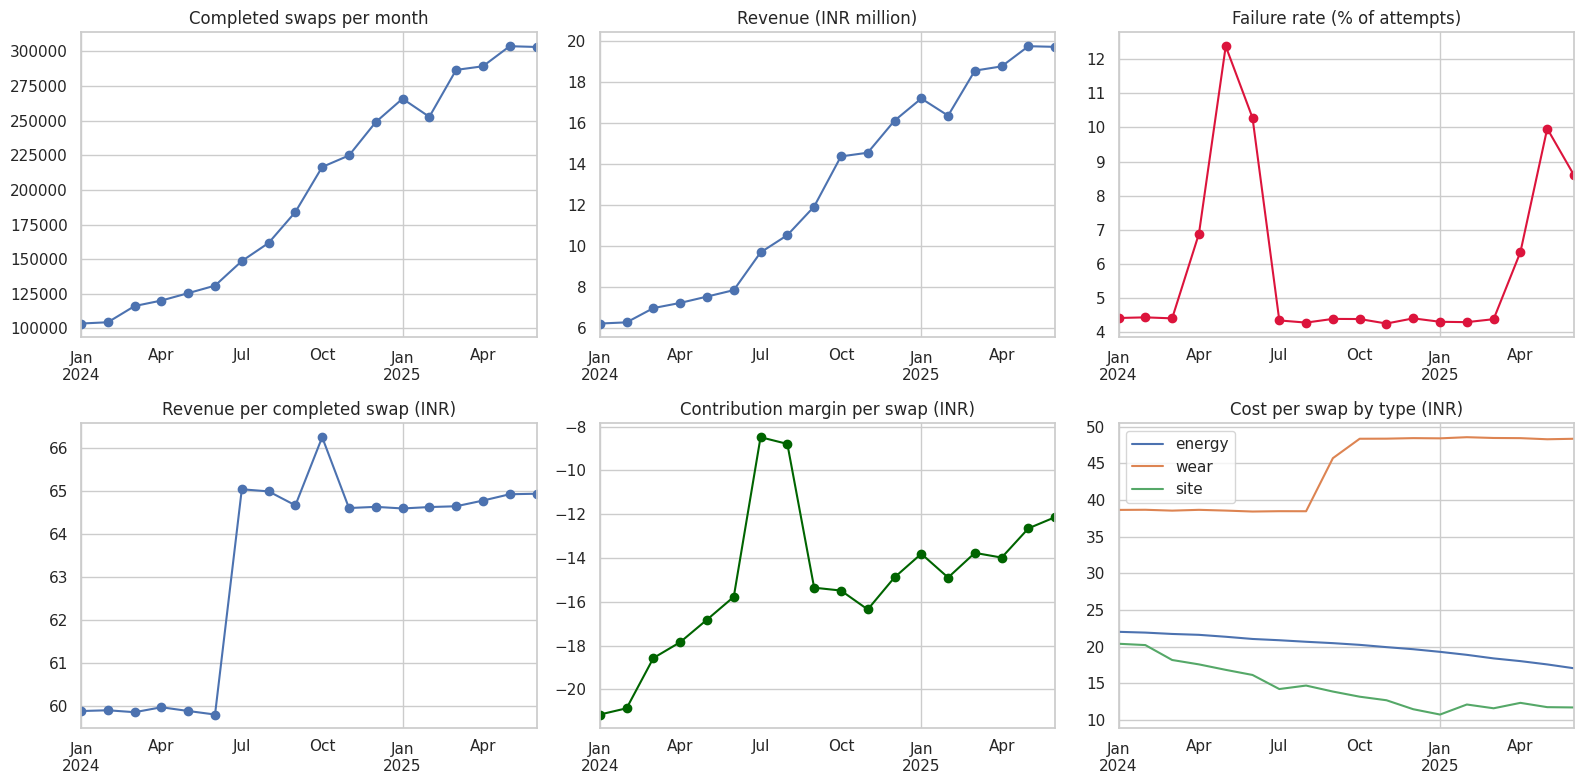

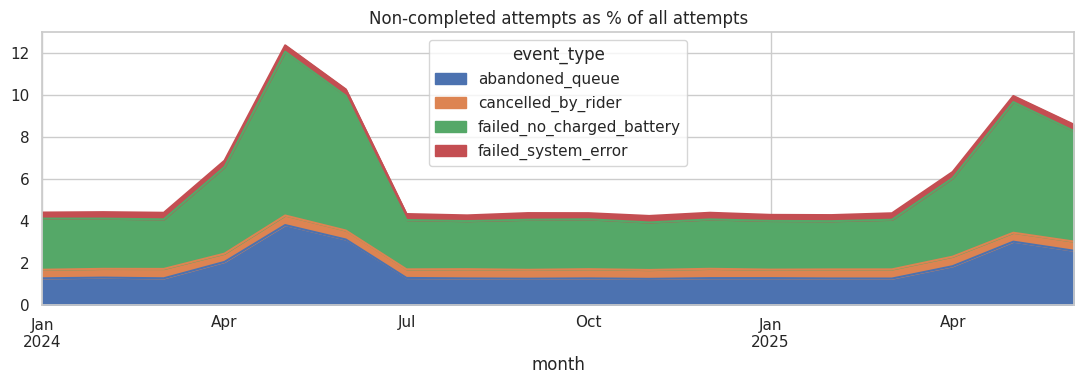

{'first_month': '2024-01', 'last_month': '2025-06', 'swaps0': np.float64(103508.0), 'swaps1': np.float64(303196.0), 'rev0': np.float64(6198803.5), 'rev1': np.float64(19690790.0), 'fail0': np.float64(0.044053270285745905), 'fail1': np.float64(0.08598542742501936), 'margin0': np.float64(-21.14987934750575), 'margin1': np.float64(-12.13128744836563), 'rps0': np.float64(59.88719229431541), 'rps1': np.float64(64.94409556854312), 'peak_margin_month': '2024-07', 'low_margin_month': '2024-01', 'failure_mix_last': {'abandoned_queue': 2.58, 'cancelled_by_rider': 0.44, 'failed_no_charged_battery': 5.27, 'failed_system_error': 0.3}}


In [ ]:
done = swaps[swaps.completed].copy()
done["energy_cost"] = done.energy_to_recharge_kwh * done.grid_tariff_inr_kwh

bat = batteries.set_index("battery_id").copy()
bat["soh_drop"] = bat.initial_soh_pct - bat.current_soh_pct
bat["wear_frac"] = (bat.soh_drop / (bat.initial_soh_pct - 70)).clip(0, 1)
bat["n_swaps"] = done.battery_out_id.value_counts().reindex(bat.index)
bat["wear_per_swap"] = bat.purchase_cost_inr * bat.wear_frac / bat.n_swaps
med_wear = bat.groupby("supplier").wear_per_swap.median()
done["wear_cost"] = done.battery_out_id.map(bat.wear_per_swap)
done["wear_cost"] = done.wear_cost.fillna(done.battery_out_id.map(bat.supplier).map(med_wear)).fillna(med_wear.median())

sm = done.groupby(["station_id", "month"]).size().rename("n_sm")
done = done.join(sm, on=["station_id", "month"])
done["site_cost"] = (done.monthly_rent_inr + done.monthly_maintenance_inr) / done.n_sm
done["margin"] = done.amount_charged_inr - done.energy_cost - done.wear_cost - done.site_cost

monthly = swaps.groupby("month").agg(attempts=("event_id", "count"), completed=("completed", "sum"))
monthly["failure_rate"] = 1 - monthly.completed / monthly.attempts
monthly = monthly.join(done.groupby("month").agg(revenue=("amount_charged_inr", "sum"), margin_total=("margin", "sum"),
                                                energy=("energy_cost", "mean"), wear=("wear_cost", "mean"), site=("site_cost", "mean")))
monthly["rev_per_swap"] = monthly.revenue / monthly.completed
monthly["margin_per_swap"] = monthly.margin_total / monthly.completed
display(monthly.round(3))

fig, ax = plt.subplots(2, 3, figsize=(16, 8))
monthly.completed.plot(ax=ax[0, 0], marker="o", title="Completed swaps per month")
(monthly.revenue / 1e6).plot(ax=ax[0, 1], marker="o", title="Revenue (INR million)")
(monthly.failure_rate * 100).plot(ax=ax[0, 2], marker="o", color="crimson", title="Failure rate (% of attempts)")
monthly.rev_per_swap.plot(ax=ax[1, 0], marker="o", title="Revenue per completed swap (INR)")
monthly.margin_per_swap.plot(ax=ax[1, 1], marker="o", color="darkgreen", title="Contribution margin per swap (INR)")
monthly[["energy", "wear", "site"]].plot(ax=ax[1, 2], title="Cost per swap by type (INR)")
for a in ax.flat: a.set_xlabel("")
show("q1_trends")

m0, m1 = monthly.iloc[0], monthly.iloc[-1]
F["q1"] = dict(first_month=str(monthly.index[0].date())[:7], last_month=str(monthly.index[-1].date())[:7],
               swaps0=m0.completed, swaps1=m1.completed, rev0=m0.revenue, rev1=m1.revenue,
               fail0=m0.failure_rate, fail1=m1.failure_rate, margin0=m0.margin_per_swap, margin1=m1.margin_per_swap,
               rps0=m0.rev_per_swap, rps1=m1.rev_per_swap,
               peak_margin_month=str(monthly.margin_per_swap.idxmax().date())[:7], low_margin_month=str(monthly.margin_per_swap.idxmin().date())[:7])
mix = swaps[swaps.failed].groupby(["month", "event_type"]).size().unstack(fill_value=0).div(monthly.attempts, axis=0) * 100
mix.plot(kind="area", figsize=(11, 4), title="Non-completed attempts as % of all attempts")
show("q1_failure_mix")
F["q1"]["failure_mix_last"] = mix.iloc[-1].round(2).to_dict()
print(F["q1"])

 ## 5. Core Q2 and Q3: service failures, stations and geography

Worst 10 stations by failure rate:


,attempts,fail_rate,no_battery_rate,avg_wait_sec,tickets,tickets_per_1000,city,location_type,charger_generation,connectivity_tier,expansion_wave,commissioned_date
station_id,,,,,,,,,,,,
STN-DEL-037,30838,0.091,0.056,242.636002,440,14.268,Delhi NCR,commercial_hub,Gen1,good,Launch,2023-06-12
STN-DEL-048,34646,0.090,0.055,243.988998,486,14.028,Delhi NCR,market,Gen1,good,Launch,2023-09-07
STN-JAI-137,44371,0.087,0.054,242.783005,585,13.184,Jaipur,commercial_hub,Gen1,fair,Launch,2023-08-16
STN-JAI-142,33319,0.087,0.052,244.334000,434,13.026,Jaipur,commercial_hub,Gen1,poor,Launch,2023-10-05
STN-JAI-141,45594,0.087,0.054,243.733994,644,14.125,Jaipur,commercial_hub,Gen1,good,Launch,2023-06-06
STN-DEL-045,32237,0.087,0.053,243.087006,483,14.983,Delhi NCR,commercial_hub,Gen1,good,Launch,2023-06-07
STN-JAI-136,29340,0.087,0.054,241.873993,367,12.509,Jaipur,transit_hub,Gen1,good,Launch,2023-07-24
STN-JAI-138,48945,0.087,0.054,243.440002,673,13.750,Jaipur,market,Gen1,poor,Launch,2023-08-26
STN-DEL-040,40335,0.086,0.052,242.694000,509,12.619,Delhi NCR,market,Gen1,fair,Launch,2023-09-08


Top 10% of stations (15) hold 24% of all failures and handle 15% of attempts


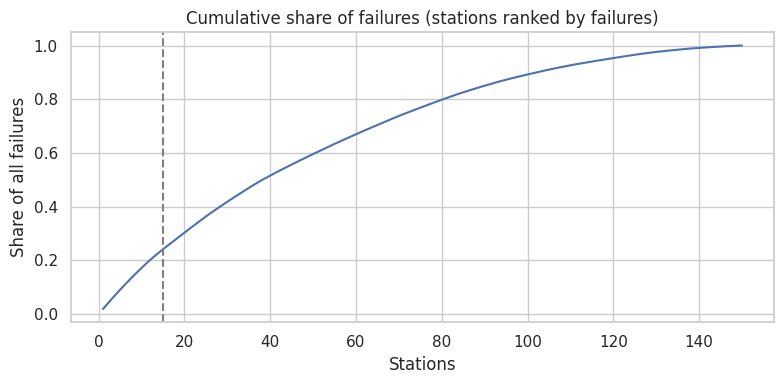

In [ ]:
stn = swaps.groupby("station_id").agg(attempts=("event_id", "count"), fail_rate=("failed", "mean"),
                                      no_battery_rate=("no_battery", "mean"), avg_wait_sec=("queue_wait_sec", "mean"))
stn["tickets"] = tickets.groupby("station_id").size()
stn["tickets_per_1000"] = stn.tickets / stn.attempts * 1000
stn = stn.join(stations.set_index("station_id")[["city", "location_type", "charger_generation", "connectivity_tier", "expansion_wave", "commissioned_date"]])
print("Worst 10 stations by failure rate:")
display(stn.sort_values("fail_rate", ascending=False).head(10).round(3))

fails_by_stn = swaps.groupby("station_id").failed.sum().sort_values(ascending=False)
share = fails_by_stn.cumsum() / fails_by_stn.sum()
top10pct = max(1, int(len(fails_by_stn) * 0.10))
top_att_share = stn.sort_values("fail_rate", ascending=False).head(top10pct).attempts.sum() / stn.attempts.sum()
print(f"Top 10% of stations ({top10pct}) hold {share.iloc[top10pct-1]:.0%} of all failures and handle {top_att_share:.0%} of attempts")
plt.figure(figsize=(8, 4)); plt.plot(range(1, len(share) + 1), share.values); plt.axvline(top10pct, ls="--", color="grey")
plt.title("Cumulative share of failures (stations ranked by failures)"); plt.xlabel("Stations"); plt.ylabel("Share of all failures")
show("q2_pareto")


== charger_generation


,attempts,fail_rate,no_battery_rate,avg_wait_sec
charger_generation,,,,
Gen1,1822034,0.0723,0.0434,242.917206
Gen2,1620707,0.0485,0.0269,242.955399
Gen3,372241,0.0484,0.0271,243.079803



== city


,attempts,fail_rate,no_battery_rate,avg_wait_sec
city,,,,
Bengaluru,763296,0.0455,0.0249,242.874405
Delhi NCR,768913,0.0735,0.0441,242.722397
Hyderabad,711930,0.0669,0.0397,242.785400
Jaipur,487634,0.0785,0.0478,243.276703
Mumbai,530299,0.0445,0.0242,243.244202
Pune,552910,0.0499,0.0280,243.007401



== location_type


,attempts,fail_rate,no_battery_rate,avg_wait_sec
location_type,,,,
commercial_hub,1535743,0.0618,0.0362,243.052002
highway_fuel_pump,329834,0.0511,0.0291,243.153000
market,1246931,0.0624,0.0364,242.959396
residential,382274,0.0545,0.0312,242.529007
tech_park,147533,0.0521,0.0297,242.533905
transit_hub,172667,0.0597,0.0343,242.858902


... (2 outputs left out)


== connectivity_tier


,attempts,fail_rate,no_battery_rate,avg_wait_sec
connectivity_tier,,,,
fair,669686,0.0630,0.0370,242.832504
good,2503439,0.0583,0.0338,242.938004
poor,641857,0.0626,0.0366,243.114899



== vehicle_class


,attempts,fail_rate,no_battery_rate,avg_wait_sec
vehicle_class,,,,
2W,3399568,0.0545,0.0312,242.973404
3W,415414,0.1039,0.0642,242.751907


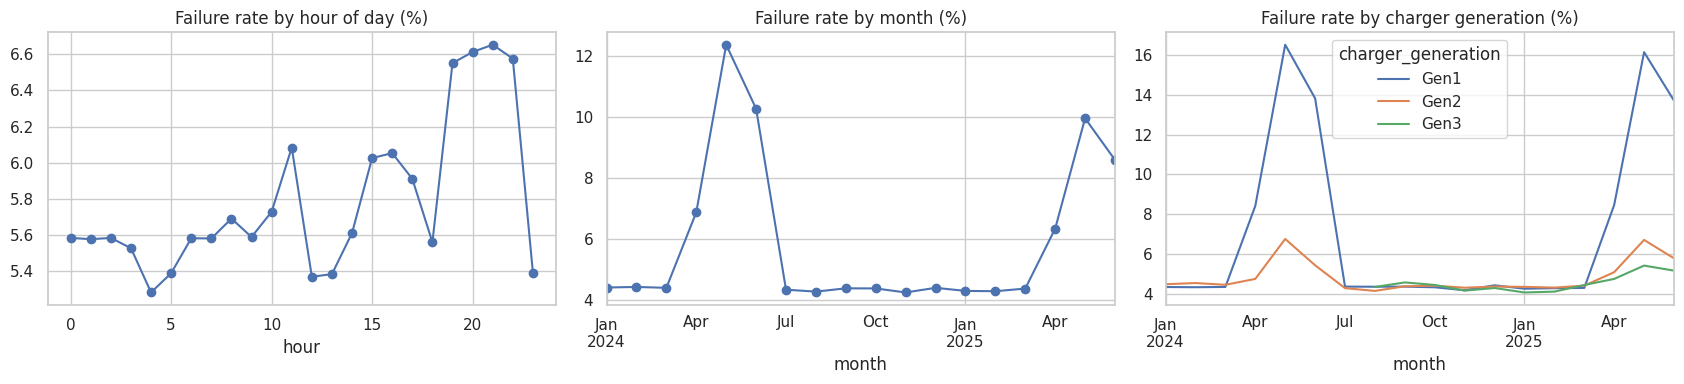

{'top10_n': 15, 'top10_fail_share': 0.2414293035255161, 'top10_attempt_share': 0.15185864572886582, 'worst_hour': 21, 'worst_hour_rate': 0.06652360515021459, 'best_hour': 4, 'best_hour_rate': 0.05282228842902005, 'longest_wait_hour': 1, 'longest_wait': 245.05801391601562, 'gen_fail': {'Gen1': 0.0723, 'Gen2': 0.0485, 'Gen3': 0.0484}, 'city_fail': {'Bengaluru': 0.0455, 'Delhi NCR': 0.0735, 'Hyderabad': 0.0669, 'Jaipur': 0.0785, 'Mumbai': 0.0445, 'Pune': 0.0499}, 'loc_fail': {'commercial_hub': 0.0618, 'highway_fuel_pump': 0.0511, 'market': 0.0624, 'residential': 0.0545, 'tech_park': 0.0521, 'transit_hub': 0.0597}, 'wave_fail': {'Launch': 0.0624, 'Wave1_2024H2': 0.0488, 'Wave2_2025H1': 0.0499}, 'veh_fail': {'2W': 0.0545, '3W': 0.1039}, 'conn_fail': {'fair': 0.063, 'good': 0.0583, 'poor': 0.0626}, 'veh_wait': {'2W': 242.97340393066406, '3W': 242.7519073486328}, 'worst_stations': ['STN-DEL-037', 'STN-DEL-048', 'STN-JAI-137', 'STN-JAI-142', 'STN-JAI-141']}


In [ ]:
def seg(col):
    return swaps.groupby(col).agg(attempts=("event_id", "count"), fail_rate=("failed", "mean"),
                                  no_battery_rate=("no_battery", "mean"), avg_wait_sec=("queue_wait_sec", "mean")).round(4)
segs = {}
for col in ["charger_generation", "city", "location_type", "expansion_wave", "connectivity_tier", "vehicle_class"]:
    segs[col] = seg(col); print("\n==", col); display(segs[col])

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
(swaps.groupby("hour").failed.mean() * 100).plot(ax=ax[0], marker="o", title="Failure rate by hour of day (%)")
(swaps.groupby("month").failed.mean() * 100).plot(ax=ax[1], marker="o", title="Failure rate by month (%)")
(swaps.groupby(["month", "charger_generation"]).failed.mean().unstack() * 100).plot(ax=ax[2], title="Failure rate by charger generation (%)")
show("q2_segments")

hr = swaps.groupby("hour").failed.mean()
wait_hr = swaps.groupby("hour").queue_wait_sec.mean()
F["q2"] = dict(top10_n=top10pct, top10_fail_share=float(share.iloc[top10pct - 1]), top10_attempt_share=float(top_att_share),
               worst_hour=int(hr.idxmax()), worst_hour_rate=float(hr.max()), best_hour=int(hr.idxmin()), best_hour_rate=float(hr.min()),
               longest_wait_hour=int(wait_hr.idxmax()), longest_wait=float(wait_hr.max()),
               gen_fail=segs["charger_generation"].fail_rate.to_dict(), city_fail=segs["city"].fail_rate.to_dict(),
               loc_fail=segs["location_type"].fail_rate.to_dict(), wave_fail=segs["expansion_wave"].fail_rate.to_dict(),
               veh_fail=segs["vehicle_class"].fail_rate.to_dict(), conn_fail=segs["connectivity_tier"].fail_rate.to_dict(),
               veh_wait=segs["vehicle_class"].avg_wait_sec.to_dict(),
               worst_stations=stn.sort_values("fail_rate", ascending=False).head(5).index.tolist())
print(F["q2"])

,avg_charge_minutes,cabinet_temp_c,stockout_2w
charger_generation,,,
Gen1,91.791,24.848,0.023
Gen2,64.229,24.637,0.004
Gen3,42.142,28.251,0.003


,avg_charge_minutes,stockout_2w
city,,
Bengaluru,71.779,0.007
Delhi NCR,80.139,0.022
Hyderabad,79.792,0.014
Jaipur,85.312,0.032
Mumbai,65.948,0.003
Pune,67.682,0.002


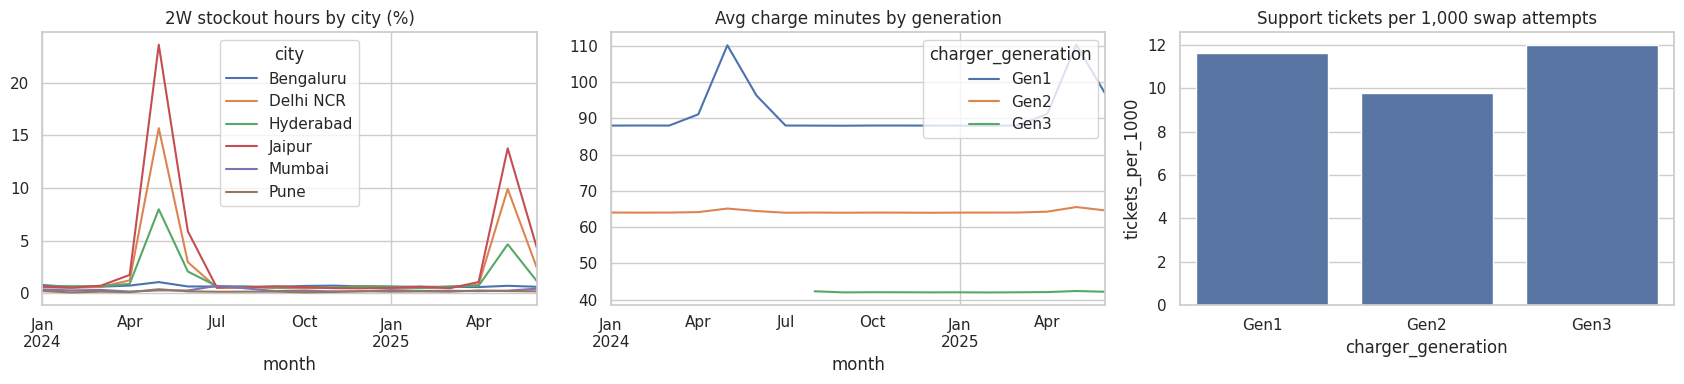

stockout_2w
False    0.0328
True     0.0726
Name: nb_rate, dtype: float64
{'charge_min': {'Gen1': 91.791, 'Gen2': 64.229, 'Gen3': 42.142}, 'stockout_gen': {'Gen1': 0.023, 'Gen2': 0.004, 'Gen3': 0.003}, 'temp_gen': {'Gen1': 24.848, 'Gen2': 24.637, 'Gen3': 28.251}, 'stockout_city': {'Bengaluru': 0.007, 'Delhi NCR': 0.022, 'Hyderabad': 0.014, 'Jaipur': 0.032, 'Mumbai': 0.003, 'Pune': 0.002}, 'tickets_per_1000_gen': {'Gen1': 11.630769692459413, 'Gen2': 9.803010357901053, 'Gen3': 11.996156596475817}, 'tickets_per_1000_city': {'Bengaluru': 9.084786938674805, 'Delhi NCR': 13.007226905100422, 'Hyderabad': 12.292796695873356, 'Jaipur': 13.226904311978426, 'Mumbai': 8.887793853767437, 'Pune': 9.57523840423144}, 'nb_rate_stockout': 0.07258854012453644, 'nb_rate_normal': 0.03283461495332807, 'peak_stockout_month': 5, 'peak_stockout_rate': 0.056975074128984435, 'normal_stockout_rate': 0.005026845891917973}


In [ ]:
# Station telemetry: charging time, stockouts, heat
h = hourly[hourly.tele_ok].merge(stations[["station_id", "city", "charger_generation", "connectivity_tier"]], on="station_id")
h["stockout_2w"] = h.charged_2w_min.eq(0)
h["month"] = h.hour_start.dt.to_period("M").dt.to_timestamp()
tele_gen = h.groupby("charger_generation")[["avg_charge_minutes", "cabinet_temp_c", "stockout_2w"]].mean().round(3)
tele_city = h.groupby("city")[["avg_charge_minutes", "stockout_2w"]].mean().round(3)
display(tele_gen); display(tele_city)

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
(h.groupby(["month", "city"]).stockout_2w.mean().unstack() * 100).plot(ax=ax[0], title="2W stockout hours by city (%)")
h.groupby(["month", "charger_generation"]).avg_charge_minutes.mean().unstack().plot(ax=ax[1], title="Avg charge minutes by generation")
sns.barplot(data=stn.reset_index(), x="charger_generation", y="tickets_per_1000", order=["Gen1", "Gen2", "Gen3"], ax=ax[2], errorbar=None)
ax[2].set_title("Support tickets per 1,000 swap attempts")
show("q3_telemetry")

swaps["hour_start"] = swaps.event_ts.dt.floor("h")
nb = swaps.groupby(["station_id", "hour_start"]).no_battery.mean().rename("nb_rate").reset_index()
j = h.merge(nb, on=["station_id", "hour_start"], how="inner")
nb_by_stockout = j.groupby("stockout_2w").nb_rate.mean()
print(nb_by_stockout.round(4))
swaps.drop(columns="hour_start", inplace=True)
mstock = h.groupby(h.month.dt.month).stockout_2w.mean()
F["q3"] = dict(charge_min=tele_gen.avg_charge_minutes.to_dict(), stockout_gen=tele_gen.stockout_2w.to_dict(), temp_gen=tele_gen.cabinet_temp_c.to_dict(),
               stockout_city=tele_city.stockout_2w.to_dict(), tickets_per_1000_gen=stn.groupby("charger_generation").tickets_per_1000.mean().to_dict(),
               tickets_per_1000_city=stn.groupby("city").tickets_per_1000.mean().to_dict(),
               nb_rate_stockout=float(nb_by_stockout.get(True, np.nan)), nb_rate_normal=float(nb_by_stockout.get(False, np.nan)),
               peak_stockout_month=int(mstock.idxmax()), peak_stockout_rate=float(mstock.max()), normal_stockout_rate=float(mstock.median()))
print(F["q3"])

 ## 6. Core Q4: battery and equipment performance

rows         km     soh_in
pack_type supplier                               
2W_2.1kWh Amptek     697797  60.810001  89.709999
          Cellora   1927916  60.810001  89.709999
          Kyron      749062  48.389999  80.349998
3W_4.8kWh Amptek      87933  90.220001  92.980003
          Cellora    218100  90.190002  92.980003
          Kyron      106316  87.699997  90.419998

supplier,Amptek,Cellora,Kyron
soh_band,,,
"(0, 60]",NaN,NaN,34.799999
"(60, 70]",NaN,NaN,38.200001
"(70, 80]",51.799999,51.799999,46.500000
"(80, 90]",57.799999,57.599998,55.799999
"(90, 101]",70.300003,70.000000,66.900002


,supplier,manufacturing_lot,packs,soh_drop,retired,km
45,Kyron,KY-2409,481,38.29,0.98,49.439999
43,Kyron,KY-2407,480,38.18,0.99,49.919998
44,Kyron,KY-2408,500,38.17,0.98,49.900002
20,Cellora,CE-2307,143,18.59,0.00,62.830002
19,Cellora,CE-2306,122,18.56,0.00,62.970001
7,Amptek,AM-2410,81,18.56,0.00,63.090000
2,Amptek,AM-2405,88,18.56,0.00,63.619999
23,Cellora,CE-2310,117,18.55,0.00,62.880001


,packs,soh_drop,retired,swaps_per_pack
supplier,,,,
Amptek,1307,18.189,0.000,600.580
Cellora,3555,18.255,0.000,604.462
Kyron,1638,35.458,0.878,398.568


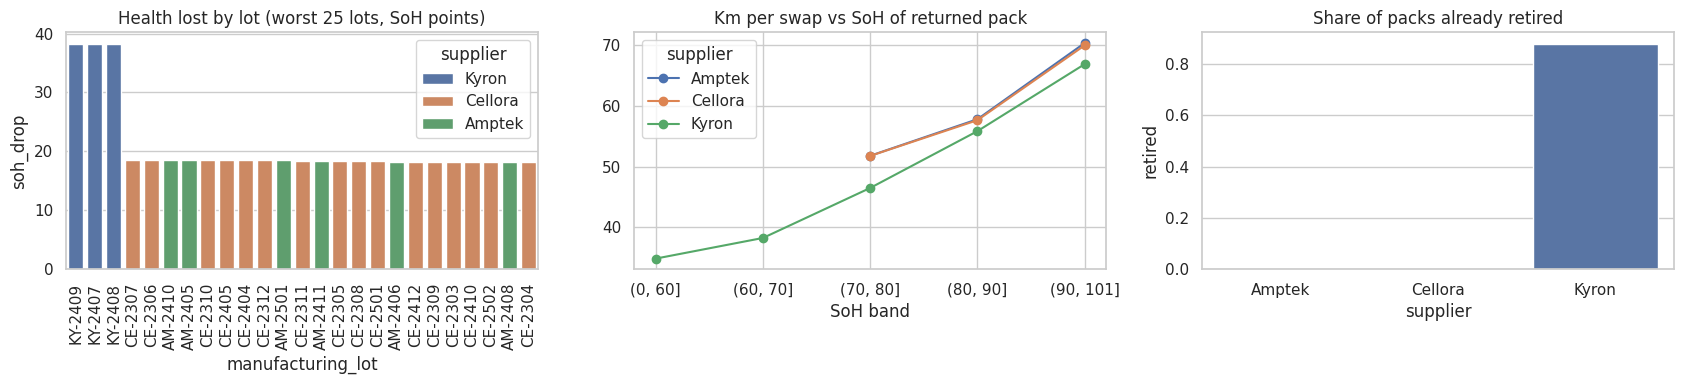

tickets per 1000 packs: {'Amptek': 4488.1, 'Cellora': 4467.8, 'Kyron': 5238.7}
low_range share of tickets: {'Amptek': 0.138, 'Cellora': 0.139, 'Kyron': 0.184}
{'sup_drop': {'Amptek': 18.18921193573068, 'Cellora': 18.254739803094232, 'Kyron': 35.457692307692305}, 'sup_retired': {'Amptek': 0.0, 'Cellora': 0.0, 'Kyron': 0.8778998778998779}, 'sup_packs': {'Amptek': 1307, 'Cellora': 3555, 'Kyron': 1638}, 'sup_km': {'Amptek': 64.10330200195312, 'Cellora': 63.79477310180664, 'Kyron': 53.27543258666992}, 'tickets_per_1000_packs': {'Amptek': 4488.14078041316, 'Cellora': 4467.791842475386, 'Kyron': 5238.705738705738}, 'bad_lots': ['KY-2409', 'KY-2407', 'KY-2408'], 'bad_lot_supplier': ['Kyron'], 'bad_lot_packs': 1461, 'bad_lot_drop': 38.21459567452067, 'other_drop': 17.273080840613474}


In [ ]:
inn = swaps[swaps.battery_in_id.notna()][["battery_in_id", "km_since_last_swap", "soh_in_pct", "soc_in_pct"]].copy()
inn["supplier"] = inn.battery_in_id.map(bat.supplier)
inn["lot"] = inn.battery_in_id.map(bat.manufacturing_lot)
inn["pack_type"] = inn.battery_in_id.map(bat.pack_type)
rng_tbl = inn.groupby(["pack_type", "supplier"]).agg(rows=("km_since_last_swap", "size"), km=("km_since_last_swap", "mean"), soh_in=("soh_in_pct", "mean")).round(2)
display(rng_tbl)

inn["soh_band"] = pd.cut(inn.soh_in_pct, [0, 60, 70, 80, 90, 101])
kmb = inn.groupby(["soh_band", "supplier"]).km_since_last_swap.mean().unstack()
display(kmb.round(1))

lot = bat.groupby(["supplier", "manufacturing_lot"]).agg(packs=("soh_drop", "size"), soh_drop=("soh_drop", "mean"),
                                                         retired=("retired_date", lambda s: s.notna().mean())).reset_index()
lot["km"] = lot.manufacturing_lot.map(inn.groupby("lot").km_since_last_swap.mean())
lot = lot.sort_values("soh_drop", ascending=False)
display(lot.head(8).round(2))
sup = bat.groupby("supplier").agg(packs=("soh_drop", "size"), soh_drop=("soh_drop", "mean"), retired=("retired_date", lambda s: s.notna().mean()),
                                  swaps_per_pack=("n_swaps", "mean"))
display(sup.round(3))

fig, ax = plt.subplots(1, 3, figsize=(17, 4))
sns.barplot(data=lot.head(25), x="manufacturing_lot", y="soh_drop", hue="supplier", ax=ax[0], dodge=False)
ax[0].set_title("Health lost by lot (worst 25 lots, SoH points)"); ax[0].tick_params(axis="x", rotation=90)
kmb.plot(ax=ax[1], marker="o", title="Km per swap vs SoH of returned pack"); ax[1].set_xlabel("SoH band")
sns.barplot(data=sup.reset_index(), x="supplier", y="retired", ax=ax[2]); ax[2].set_title("Share of packs already retired")
show("q4_batteries")

tk = tickets.dropna(subset=["battery_id"]).copy()
tk["supplier"] = tk.battery_id.map(bat.supplier)
tk_sup = tk.groupby("supplier").size() / bat.groupby("supplier").size() * 1000
lowrange_share = tk[tk.category == "low_range"].groupby("supplier").size() / tk.groupby("supplier").size()
print("tickets per 1000 packs:", tk_sup.round(1).to_dict()); print("low_range share of tickets:", lowrange_share.round(3).to_dict())
bad_lots = lot[lot.soh_drop > lot.soh_drop.median() * 1.5]
F["q4"] = dict(sup_drop=sup.soh_drop.to_dict(), sup_retired=sup.retired.to_dict(), sup_packs=sup.packs.to_dict(),
               sup_km=inn.groupby("supplier").km_since_last_swap.mean().to_dict(), tickets_per_1000_packs=tk_sup.to_dict(),
               bad_lots=bad_lots.manufacturing_lot.tolist(), bad_lot_supplier=bad_lots.supplier.unique().tolist(),
               bad_lot_packs=int(bad_lots.packs.sum()), bad_lot_drop=float(bad_lots.soh_drop.mean()) if len(bad_lots) else np.nan,
               other_drop=float(lot[~lot.manufacturing_lot.isin(bad_lots.manufacturing_lot)].soh_drop.mean()))
print(F["q4"])

 ## 7. Core Q5: pricing and partner economics

Months where median list price changed: {'2024-07': 65.0} | first value 60.0


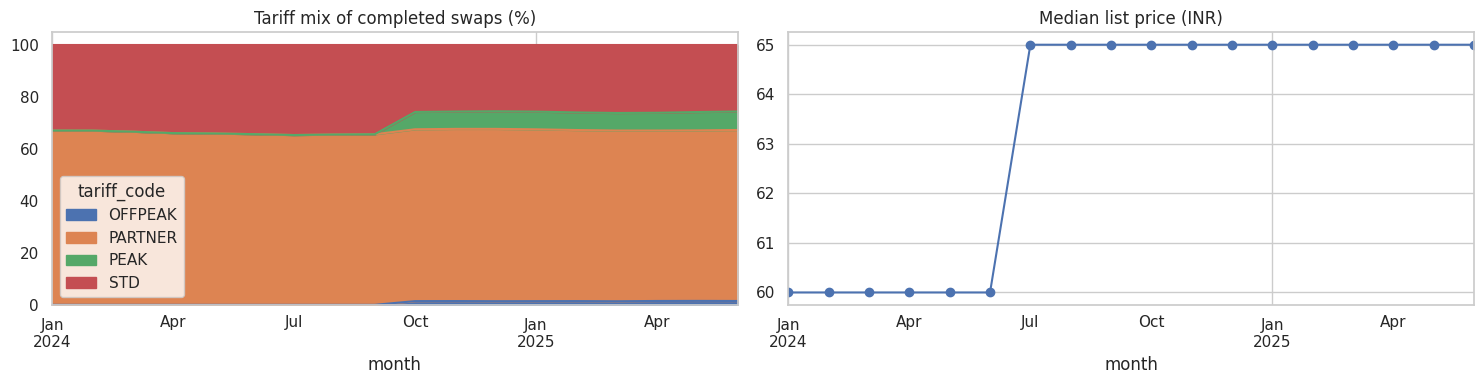

In [ ]:
# 7.1 tariff mix and base price over time
tmix = done.groupby(["month", "tariff_code"]).size().unstack(fill_value=0)
tmix_pct = tmix.div(tmix.sum(axis=1), axis=0) * 100
price_med = done.groupby("month").list_price_inr.median()
chg = price_med[price_med.diff().fillna(0) != 0]
print("Months where median list price changed:", {str(k.date())[:7]: float(v) for k, v in chg.items()}, "| first value", float(price_med.iloc[0]))

fig, ax = plt.subplots(1, 2, figsize=(15, 4))
tmix_pct.plot(kind="area", ax=ax[0], title="Tariff mix of completed swaps (%)")
price_med.plot(ax=ax[1], marker="o", title="Median list price (INR)")
show("q5_tariff_price")

peak_share      price  margin    swaps
segment              group   period                                        
fleet-partner riders control post         0.556  60.910000 -23.106  1036367
                             pre          0.547  60.750000 -20.607   494126
                     pilot   post         0.548  64.630997  -9.285   541863
                             pre          0.575  60.563999 -15.553   295798
independent riders   control post         0.613  67.348000 -12.306   536729
                             pre          0.614  64.443001 -10.482   265559
                     pilot   post         0.592  75.387001   6.879   276822
                             pre          0.617  64.454002  -5.618   139411

Difference-in-differences: {('independent riders', 'peak_share'): -0.02400000000000002, ('independent riders', 'price'): 8.027999877929688, ('independent riders', 'margin'): 14.321, ('fleet-partner riders', 'peak_share'): -0.03599999999999992, ('fleet-partner riders', 'price'): 3.9069976806640625, ('fleet-partner riders', 'margin'): 8.767000000000003}


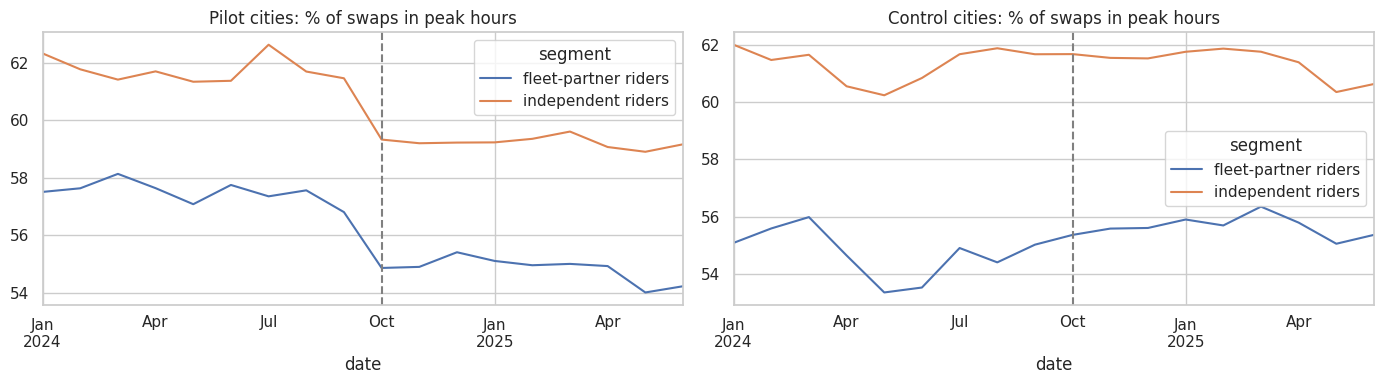

In [ ]:
# 7.2 peak/off-peak pilot: find pilot cities and dates from the data, then difference-in-differences
tp = done[done.tariff_code.isin(["PEAK", "OFFPEAK"])]
pilot_counts = tp.groupby("city").size()
pilot_cities = pilot_counts[pilot_counts >= 500].index.tolist()
F["q5"] = dict(price_change_months=[str(k.date())[:7] for k in chg.index], price_first=float(price_med.iloc[0]), price_last=float(price_med.iloc[-1]),
               pilot_cities=pilot_cities)
if pilot_cities:
    pilot_date = tp[tp.city.isin(pilot_cities)].date.min()
    share_peak = tp.groupby("hour").tariff_code.apply(lambda s: (s == "PEAK").mean())
    peak_hours = share_peak[share_peak > 0.5].index.tolist()
    d = done.copy()
    d["in_peak"] = d.hour.isin(peak_hours)
    d["group"] = np.where(d.city.isin(pilot_cities), "pilot", "control")
    d["period"] = np.where(d.date >= pilot_date, "post", "pre")
    d["segment"] = np.where(d.partner_id.notna(), "fleet-partner riders", "independent riders")
    did_tbl = d.groupby(["segment", "group", "period"]).agg(peak_share=("in_peak", "mean"), price=("amount_charged_inr", "mean"), margin=("margin", "mean"),
                                                            swaps=("event_id", "size")).round(3)
    display(did_tbl)
    did = {}
    for seg_name in ["independent riders", "fleet-partner riders"]:
        for metric in ["peak_share", "price", "margin"]:
            t = did_tbl.loc[seg_name][metric]
            try:
                did[(seg_name, metric)] = float((t["pilot", "post"] - t["pilot", "pre"]) - (t["control", "post"] - t["control", "pre"]))
            except KeyError:
                did[(seg_name, metric)] = np.nan
    print("Difference-in-differences:", did)
    F["q5"].update(pilot_date=str(pilot_date.date()), peak_hours=peak_hours,
                   did_indep_peak=did[("independent riders", "peak_share")], did_indep_price=did[("independent riders", "price")], did_indep_margin=did[("independent riders", "margin")],
                   did_fleet_peak=did[("fleet-partner riders", "peak_share")], did_fleet_price=did[("fleet-partner riders", "price")], did_fleet_margin=did[("fleet-partner riders", "margin")])
    pv = d[d.group == "pilot"].groupby([d.date.dt.to_period("M").dt.to_timestamp(), "segment"]).in_peak.mean().unstack() * 100
    cv = d[d.group == "control"].groupby([d.date.dt.to_period("M").dt.to_timestamp(), "segment"]).in_peak.mean().unstack() * 100
    fig, ax = plt.subplots(1, 2, figsize=(14, 4))
    pv.plot(ax=ax[0], title="Pilot cities: % of swaps in peak hours"); cv.plot(ax=ax[1], title="Control cities: % of swaps in peak hours")
    for a in ax: a.axvline(pilot_date, ls="--", color="grey")
    show("q5_pilot_did")
else:
    print("No PEAK/OFFPEAK volume found, pilot section skipped.")

,swaps,avg_price,avg_discount_pct,energy,wear,site,margin_per_swap,total_margin,swap_share_pct,margin_pct_of_price
partner_name,,,,,,,,,,
CargoTuk,131334,99.459999,8.000000,40.80,85.49,13.78,-40.61,-5333018.40,3.66,-40.83
HaulKing,53120,100.360001,7.000000,40.77,85.62,13.87,-39.90,-2119572.53,1.48,-39.76
ZipDrop,549390,52.070000,21.799999,19.14,43.48,12.84,-23.39,-12851726.06,15.32,-44.93
ParcelNest,296209,56.509998,15.000000,18.13,43.35,13.52,-18.48,-5473436.71,8.26,-32.70
MetroMove,81916,58.980000,12.000000,18.35,44.05,13.56,-16.99,-1391343.91,2.28,-28.80
Swiggle Go,237632,59.299999,11.000000,18.36,43.30,13.55,-15.91,-3779726.88,6.63,-26.82
LastMileHub,80332,60.720001,10.000000,18.69,44.51,12.93,-15.41,-1238195.79,2.24,-25.38
FeastFly,516367,62.029999,10.000000,18.21,43.22,13.44,-12.84,-6630739.44,14.40,-20.70
RideMitra,119503,62.709999,6.000000,17.94,43.00,13.83,-12.05,-1439879.14,3.33,-19.21


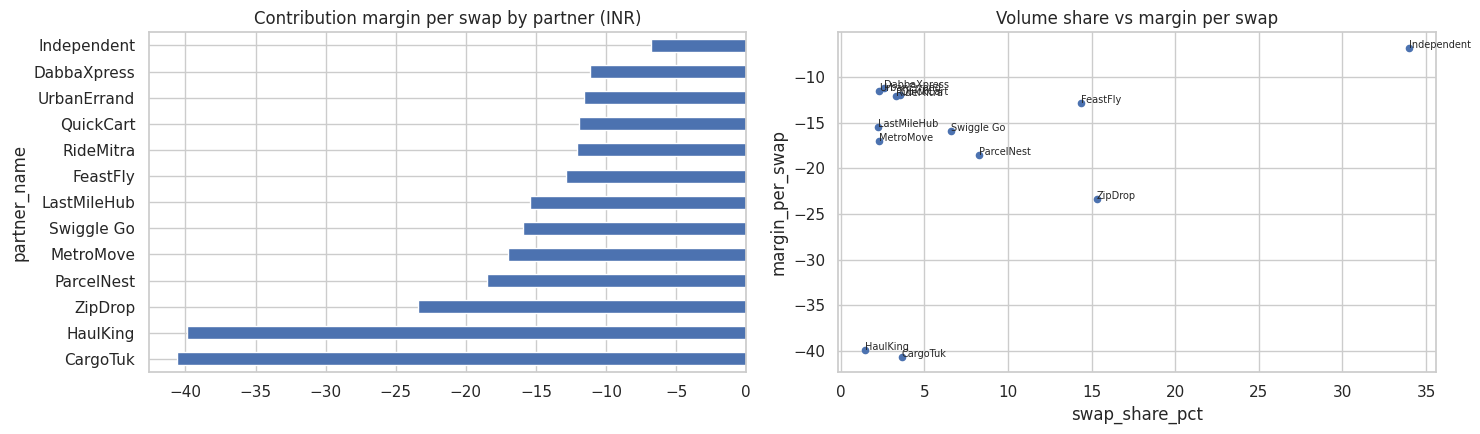

,partner,period,swaps,discount_pct,margin_per_swap
0,ZipDrop,before,212968,12.0,-17.58
1,ZipDrop,after,336422,28.0,-27.08


In [ ]:
# 7.3 partner economics
pname = partners.set_index("partner_id").partner_name
done["partner_name"] = done.partner_id.map(pname).fillna("Independent")
done["disc_pct"] = done.discount_inr / done.list_price_inr * 100
ptab = done.groupby("partner_name").agg(swaps=("event_id", "size"), avg_price=("amount_charged_inr", "mean"), avg_discount_pct=("disc_pct", "mean"),
                                        energy=("energy_cost", "mean"), wear=("wear_cost", "mean"), site=("site_cost", "mean"),
                                        margin_per_swap=("margin", "mean"), total_margin=("margin", "sum"))
ptab["swap_share_pct"] = ptab.swaps / ptab.swaps.sum() * 100
ptab["margin_pct_of_price"] = ptab.margin_per_swap / ptab.avg_price * 100
ptab = ptab.sort_values("margin_per_swap")
display(ptab.round(2))
fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
ptab.margin_per_swap.plot(kind="barh", ax=ax[0], title="Contribution margin per swap by partner (INR)")
ptab.plot.scatter(x="swap_share_pct", y="margin_per_swap", ax=ax[1], title="Volume share vs margin per swap")
for k, rrow in ptab.iterrows(): ax[1].annotate(k, (rrow.swap_share_pct, rrow.margin_per_swap), fontsize=7)
show("q5_partners")

part_only = ptab.drop(index="Independent", errors="ignore")
big = part_only.swaps.idxmax()
F["q5"].update(partner_lowest=part_only.margin_per_swap.idxmin(), partner_lowest_margin=float(part_only.margin_per_swap.min()),
               partner_highest=part_only.margin_per_swap.idxmax(), partner_highest_margin=float(part_only.margin_per_swap.max()),
               biggest_partner=big, biggest_share=float(part_only.loc[big, "swap_share_pct"]), biggest_margin=float(part_only.loc[big, "margin_per_swap"]),
               biggest_margin_rank=int((part_only.margin_per_swap > part_only.loc[big, "margin_per_swap"]).sum() + 1), n_partners=len(part_only),
               indep_margin=float(ptab.loc["Independent", "margin_per_swap"]) if "Independent" in ptab.index else np.nan,
               indep_price=float(ptab.loc["Independent", "avg_price"]) if "Independent" in ptab.index else np.nan)

# contract amendment (e.g. ZipDrop, Nov 2024)
amended = partners.dropna(subset=["amendment_date"])
am_rows = []
for _, a in amended.iterrows():
    sub = done[done.partner_id == a.partner_id]
    for lbl, s in [("before", sub[sub.date < a.amendment_date]), ("after", sub[sub.date >= a.amendment_date])]:
        am_rows.append(dict(partner=a.partner_name, period=lbl, swaps=len(s), discount_pct=s.disc_pct.mean(), margin_per_swap=s.margin.mean()))
am = pd.DataFrame(am_rows); display(am.round(2))
F["q5"]["amendments"] = am.round(2).to_dict("records")

 ## 8. Core Q6: root causes of new-rider churn
 **Population:** riders who signed up in 2024 or later and whose first-ever attempt is early enough (on or before 1 May 2025) to observe 60 days.
 **Not returning (churn):** no completed swap between day 30 and day 60 after the rider's first attempt.
 **Predictors:** only what happened in the **first 14 days** (so the outcome window never leaks into the predictors) plus static rider attributes.

Riders analysed: 13,797 | churn rate: 14.6%

== first-14-day failure rate


,mean,size
fail_bucket,,
none,0.133,6930
<=10%,0.113,4220
10-25%,0.213,2335
>25%,0.385,312



== avg_wait_sec_14d


,churn_rate,riders
avg_wait_sec_14d,,
"(0.999, 211.481]",0.175,3450
"(211.481, 238.529]",0.121,3450
"(238.529, 268.35]",0.124,3448
"(268.35, 860.0]",0.165,3449



== avg_price_paid


,churn_rate,riders
avg_price_paid,,
"(46.174, 57.2]",0.161,3804
"(57.2, 60.0]",0.136,3431
"(60.0, 65.056]",0.130,3111
"(65.056, 125.0]",0.154,3447


... (8 outputs left out)


== home_city


,churn_rate,riders
home_city,,
Bengaluru,0.133,3016
Delhi NCR,0.153,2713
Hyderabad,0.157,2372
Jaipur,0.163,1731
Mumbai,0.127,1964
Pune,0.149,2001



== is_partner


,churn_rate,riders
is_partner,,
0,0.131,5338
1,0.156,8459


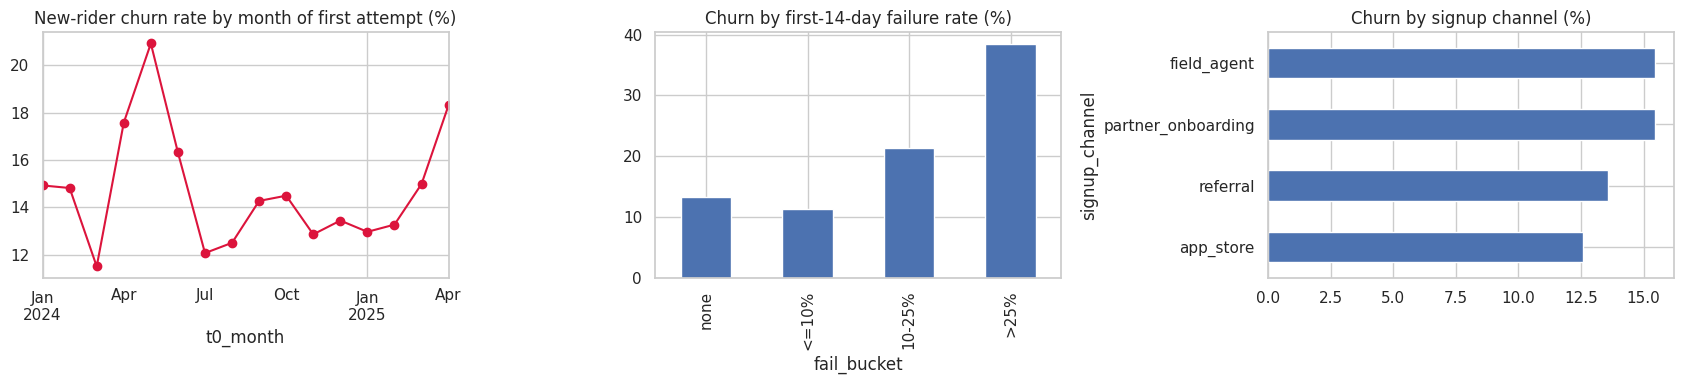

In [ ]:
ev = swaps[["rider_id", "event_ts", "date", "completed", "failed", "no_battery", "queue_wait_sec", "amount_charged_inr", "discount_inr",
            "list_price_inr", "connectivity_tier", "charger_generation", "city", "tariff_code"]].copy()
t0 = ev.groupby("rider_id").event_ts.min().rename("t0")
ev = ev.join(t0, on="rider_id")
ev["day"] = (ev.event_ts - ev.t0).dt.total_seconds() / 86400
ev = ev.merge(city_ctx[["city", "date", "competitor_promo_active", "heat_alert"]], on=["city", "date"], how="left")

f14 = ev[ev.day < 14]
g = f14.groupby("rider_id")
X = pd.DataFrame({"attempts_14d": g.size(), "fail_rate_14d": g.failed.mean(), "no_battery_rate_14d": g.no_battery.mean(),
                  "avg_wait_sec_14d": g.queue_wait_sec.mean(), "max_wait_sec_14d": g.queue_wait_sec.max(),
                  "poor_connectivity_share": g.connectivity_tier.apply(lambda s: (s == "poor").mean()),
                  "gen1_share": g.charger_generation.apply(lambda s: (s == "Gen1").mean()),
                  "competitor_promo_share": g.competitor_promo_active.apply(lambda s: s.fillna(False).astype(float).mean())})
fc = f14[f14.completed].groupby("rider_id")
X["completed_14d"] = fc.size(); X["completed_14d"] = X.completed_14d.fillna(0)
X["avg_price_paid"] = fc.amount_charged_inr.mean()
X["avg_discount_pct"] = fc.apply(lambda d_: (d_.discount_inr / d_.list_price_inr).mean() * 100)
X["peak_tariff_share"] = fc.tariff_code.apply(lambda s: (s == "PEAK").mean())
X["first_attempt_failed"] = ev[ev.event_ts == ev.t0].groupby("rider_id").failed.max().astype(float)

returned = ev[(ev.completed) & (ev.day >= 30) & (ev.day < 60)].rider_id.unique()
R = X.join(t0).join(riders.set_index("rider_id")[["signup_date", "signup_channel", "plan_type", "vehicle_class", "home_city", "kyc_verified", "age_band", "declared_shift", "partner_id"]])
R["is_partner"] = R.partner_id.notna().astype(int)
R = R[(R.signup_date >= "2024-01-01") & (R.t0 <= "2025-05-01")].copy()
R["churned"] = (~R.index.isin(returned)).astype(int)
R["t0_month"] = R.t0.dt.to_period("M").dt.to_timestamp()
print(f"Riders analysed: {len(R):,} | churn rate: {R.churned.mean():.1%}")

def churn_by(col, q=None):
    s = pd.qcut(R[col], q, duplicates="drop") if q else R[col]
    return R.groupby(s).churned.agg(["mean", "size"]).rename(columns={"mean": "churn_rate", "size": "riders"}).round(3)

for col, q in [("fail_rate_14d", None), ("avg_wait_sec_14d", 4), ("avg_price_paid", 4), ("avg_discount_pct", 4)]:
    if col == "fail_rate_14d":
        R["fail_bucket"] = pd.cut(R.fail_rate_14d, [-0.01, 0, 0.1, 0.25, 1.01], labels=["none", "<=10%", "10-25%", ">25%"])
        print("\n== first-14-day failure rate"); display(R.groupby("fail_bucket").churned.agg(["mean", "size"]).round(3))
    else:
        print("\n==", col); display(churn_by(col, q))
for col in ["signup_channel", "plan_type", "vehicle_class", "home_city", "is_partner"]:
    print("\n==", col); display(churn_by(col))

# churn by month of first attempt (is retention getting worse?)
cm = R.groupby("t0_month").churned.mean() * 100
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
cm.plot(ax=ax[0], marker="o", color="crimson", title="New-rider churn rate by month of first attempt (%)")
R.groupby("fail_bucket").churned.mean().mul(100).plot(kind="bar", ax=ax[1], title="Churn by first-14-day failure rate (%)")
R.groupby("signup_channel").churned.mean().mul(100).sort_values().plot(kind="barh", ax=ax[2], title="Churn by signup channel (%)")
show("q6_churn_descriptive")

Model AUC on held-out riders: 0.647


,0
completed_14d,0.0186
fail_rate_14d,0.0184
attempts_14d,0.0150
no_battery_rate_14d,0.0039
avg_price_paid,0.0031
home_city,0.0020
peak_tariff_share,0.0018
avg_discount_pct,0.0013
plan_type,0.0011
gen1_share,0.0004


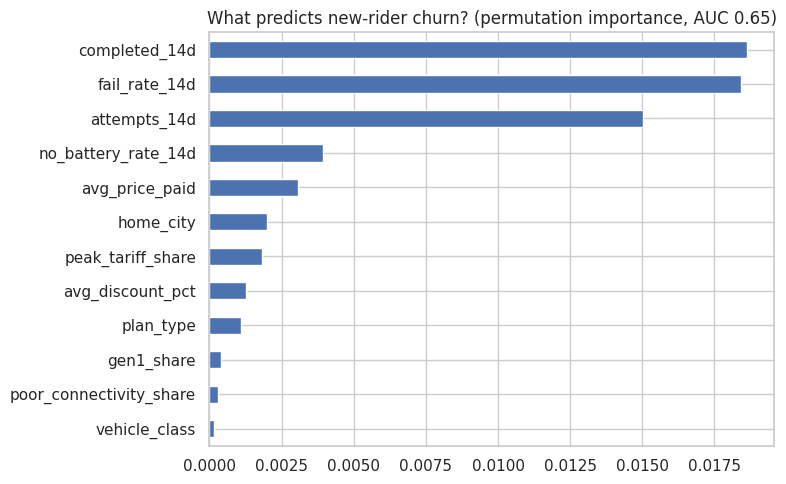

{'n_riders': 13797, 'churn_rate': 0.14619120098572153, 'auc': 0.6472979765509018, 'importance': {'completed_14d': 0.0186, 'fail_rate_14d': 0.0184, 'attempts_14d': 0.015, 'no_battery_rate_14d': 0.0039, 'avg_price_paid': 0.0031, 'home_city': 0.002, 'peak_tariff_share': 0.0018, 'avg_discount_pct': 0.0013, 'plan_type': 0.0011, 'gen1_share': 0.0004}, 'churn_by_month_first': 14.922813036020582, 'churn_by_month_last': 18.32129963898917, 'churn_by_fail_bucket': {'none': 0.133, '<=10%': 0.113, '10-25%': 0.213, '>25%': 0.385}, 'churn_by_channel': {'app_store': 0.126, 'field_agent': 0.154, 'partner_onboarding': 0.154, 'referral': 0.136}, 'churn_by_plan': {'partner_billed': 0.156, 'pay_as_you_go': 0.13, 'prepaid_pack': 0.135}, 'churn_by_partner': {0: 0.131, 1: 0.156}, 'churn_by_wait_q': [0.175, 0.121, 0.124, 0.165], 'churn_by_price_q': [0.161, 0.136, 0.13, 0.154], 'churn_by_promo': [0.147, 0.093, 0.144]}


In [ ]:
# model + permutation importance to rank drivers
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance

cat_cols = ["signup_channel", "plan_type", "vehicle_class", "home_city"]
num_cols = ["attempts_14d", "fail_rate_14d", "no_battery_rate_14d", "avg_wait_sec_14d", "max_wait_sec_14d", "poor_connectivity_share", "gen1_share",
            "competitor_promo_share", "completed_14d", "avg_price_paid", "avg_discount_pct", "peak_tariff_share", "first_attempt_failed", "is_partner"]
Xm = R[cat_cols + num_cols].copy()
for c in cat_cols: Xm[c] = Xm[c].astype("category")
y = R.churned
Xtr, Xte, ytr, yte = train_test_split(Xm, y, test_size=0.3, random_state=0, stratify=y)
clf = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, categorical_features="from_dtype", random_state=0).fit(Xtr, ytr)
auc = roc_auc_score(yte, clf.predict_proba(Xte)[:, 1])
pi = permutation_importance(clf, Xte, yte, scoring="roc_auc", n_repeats=5, random_state=0)
imp = pd.Series(pi.importances_mean, index=Xm.columns).sort_values(ascending=False)
print(f"Model AUC on held-out riders: {auc:.3f}"); display(imp.head(12).round(4))
imp.head(12)[::-1].plot(kind="barh", figsize=(8, 5), title=f"What predicts new-rider churn? (permutation importance, AUC {auc:.2f})")
show("q6_importance")

top = imp.head(8)
F["q6"] = dict(n_riders=len(R), churn_rate=float(R.churned.mean()), auc=float(auc), importance=imp.head(10).round(4).to_dict(),
               churn_by_month_first=float(cm.iloc[0]), churn_by_month_last=float(cm.iloc[-1]),
               churn_by_fail_bucket=R.groupby("fail_bucket").churned.mean().round(3).to_dict(),
               churn_by_channel=R.groupby("signup_channel").churned.mean().round(3).to_dict(),
               churn_by_plan=R.groupby("plan_type").churned.mean().round(3).to_dict(),
               churn_by_partner=R.groupby("is_partner").churned.mean().round(3).to_dict(),
               churn_by_wait_q=churn_by("avg_wait_sec_14d", 4).churn_rate.tolist(),
               churn_by_price_q=churn_by("avg_price_paid", 4).churn_rate.tolist(),
               churn_by_promo=R.assign(pb=pd.cut(R.competitor_promo_share, [-0.01, 0, 0.2, 1.01])).groupby("pb").churned.mean().round(3).tolist())
print(F["q6"])

 ## 9. Anomalies worth flagging

In [ ]:
z = (stn.fail_rate - stn.fail_rate.mean()) / stn.fail_rate.std()
anom_st = stn.assign(z=z).loc[z > 2.5, ["city", "charger_generation", "connectivity_tier", "attempts", "fail_rate", "z"]].sort_values("z", ascending=False)
print("Stations with unusually high failure rate (z > 2.5):"); display(anom_st.round(3))
daily_f = swaps.groupby("date").failed.mean()
zd = (daily_f - daily_f.rolling(28, min_periods=14).median()) / daily_f.rolling(28, min_periods=14).std()
spikes = daily_f[zd > 3]
print("Days with unusual failure spikes:", [str(k.date()) for k in spikes.index[:15]])
fw = swaps[swaps.station_firmware == "v3.2.0"].groupby("month").failed.mean() * 100
print("Failure rate on firmware v3.2.0 by month:"); display(fw.round(2).tail(8))
F["anom"] = dict(n_stations=len(anom_st), stations=anom_st.index.tolist()[:5], spike_days=[str(k.date()) for k in spikes.index[:8]])

Stations with unusually high failure rate (z > 2.5):


,city,charger_generation,connectivity_tier,attempts,fail_rate,z
station_id,,,,,,


Days with unusual failure spikes: ['2024-04-01', '2024-04-02', '2024-05-01', '2025-04-01', '2025-04-03', '2025-04-05']
Failure rate on firmware v3.2.0 by month:


,failed
month,
2024-11-01,4.29
2024-12-01,4.48
2025-01-01,4.34
2025-02-01,4.27
2025-03-01,4.40
2025-04-01,6.18
2025-05-01,9.73
2025-06-01,8.35


 ## 10. Key findings, report and video script (auto-built from the numbers above)
 This cell turns the findings dictionary `F` into a Word report, a Markdown copy and a 3-minute video script.
 **Read the text it writes and edit anything that does not match what you see in the charts before you submit.**

In [ ]:
try:
    import docx
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "python-docx"], check=True)
    import docx
from docx.shared import Inches

MONTHS = {1: "January", 2: "February", 3: "March", 4: "April", 5: "May", 6: "June", 7: "July", 8: "August", 9: "September", 10: "October", 11: "November", 12: "December"}
LABEL = {"attempts_14d": "how often they tried in the first 14 days", "fail_rate_14d": "failure rate in their first 14 days",
         "no_battery_rate_14d": "'no charged battery' failures in their first 14 days", "avg_wait_sec_14d": "average queue wait in the first 14 days",
         "max_wait_sec_14d": "longest queue wait in the first 14 days", "poor_connectivity_share": "share of swaps at poor-connectivity stations",
         "gen1_share": "share of swaps at old Gen1 stations", "competitor_promo_share": "exposure to competitor promotions",
         "completed_14d": "number of successful swaps in the first 14 days", "avg_price_paid": "price paid per swap",
         "avg_discount_pct": "discount received", "peak_tariff_share": "share of swaps at peak tariff", "first_attempt_failed": "whether the very first attempt failed",
         "is_partner": "being a fleet-partner rider", "signup_channel": "signup channel", "plan_type": "plan type",
         "vehicle_class": "vehicle class (2W/3W)", "home_city": "home city"}

def n(x, d=1):
    try:
        return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x:,.{d}f}"
    except Exception:
        return str(x)
def pc(x, d=1): return "n/a" if x is None or (isinstance(x, float) and np.isnan(x)) else f"{x*100:.{d}f}%"
def move(a, b, kind="pct"):
    if kind == "pct":
        r = (b - a) / a if a else np.nan
        return f"{'rose' if r > 0 else 'fell'} {abs(r)*100:.0f}% (from {n(a,0) if abs(a)>100 else n(a,2)} to {n(b,0) if abs(b)>100 else n(b,2)})"
    return f"{'rose' if b > a else 'fell'} from {pc(a)} to {pc(b)}"
def dkey_max(d): return max(d, key=lambda k: d[k]);
def dkey_min(d): return min(d, key=lambda k: d[k])

q1, q2, q3, q4, q5, q6 = F["q1"], F["q2"], F["q3"], F["q4"], F["q5"], F["q6"]
cl = F["clean_log"]
margin_dir = "fell" if q1["margin1"] < q1["margin0"] else "rose"

S = []   # (heading, [paragraphs or ('b', bullet)], [figure names])

S.append(("1. Problem understanding", [
    "VoltRelay Energy runs a battery-swapping network for electric two- and three-wheelers in six Indian cities. Between January 2024 and June 2025 it expanded its stations, "
    "changed its base price, piloted peak/off-peak pricing, added a battery supplier and renegotiated its largest fleet contract. Leadership sees growth in swaps and revenue "
    "but also more service failures, weaker new-rider retention and thinner per-swap profit, and wants to know what is really driving this before it commits its next operating budget.",
    "This analysis answers three questions: how the network performed, which factors are associated with failures, churn and margin erosion (and which are primary versus secondary), "
    "and what VoltRelay should prioritise. The data is observational, so the findings are evidence-based associations, not proof of causation."], []))

S.append(("2. Analytical approach", [
    f"Data: {n(F['raw_rows'],0)} swap attempts plus station, battery, rider, ticket, fleet-partner, weather and hourly telemetry tables (Jan 2024 to Jun 2025).",
    ("b", f"Cleaning: removed {n(cl['test_station_swap_rows_removed'],0)} test-station rows; corrected {n(cl['timestamps_corrected'],0)} timestamps hit by the firmware logging bug (+5h30m); "
          f"removed {n(cl['near_duplicates_removed'],0)} near-duplicate offline-sync records; nulled {n(cl['km_outliers_set_to_null'],0)} impossible distance readings; "
          f"capped {n(cl['soc_soh_readings_capped_at_100'],0)} charge/health readings above 100%; standardised {n(cl['rider_city_spellings_fixed'],0)} inconsistent rider city spellings; "
          f"excluded {n(cl['tickets_outside_window_removed'],0)} tickets outside the study window. Telemetry blanks were never treated as zero."),
    ("b", "Revenue and margin use completed swaps only. Contribution margin per swap = amount charged - grid energy - battery wear - site cost. Battery wear is purchase cost times the share of usable "
          "life used (health falling from its starting level to 70%), spread over the swaps each pack issued; site cost is monthly rent plus maintenance spread over each station-month's swaps."),
    ("b", "Failure analysis: failure and wait-time rates split by station, hour, month, vehicle class, city, charger generation, location type, expansion wave and connectivity tier, with hourly stock telemetry."),
    ("b", "Pricing: tariff mix and list price over time; the peak/off-peak pilot is evaluated with a difference-in-differences comparison of pilot versus control cities before and after launch; partner margins are computed per contract."),
    ("b", "Retention: new riders (signed up from 2024) are followed for 60 days after their first attempt. 'Churn' means no completed swap between day 30 and day 60. Predictors come only from the first 14 days "
          "plus rider attributes, and a gradient-boosting model with permutation importance ranks which factors matter most.")], []))

ins = []
ins.append(f"Completed swaps {move(q1['swaps0'], q1['swaps1'])} and revenue {move(q1['rev0'], q1['rev1'])} between {q1['first_month']} and {q1['last_month']}. "
           f"The failure rate {move(q1['fail0'], q1['fail1'], 'pts')}, and contribution margin per swap {margin_dir} from INR {n(q1['margin0'],2)} to INR {n(q1['margin1'],2)}. "
           f"Revenue per swap went from INR {n(q1['rps0'],2)} to INR {n(q1['rps1'],2)}, so volume growth and unit economics are telling different stories.")
S.append(("3. Key insights", [], []))
S.append(("3.1 Network performance over time (Q1)", [ins[0]], ["q1_trends", "q1_failure_mix"]))

conc = "concentrated in a small set of stations" if q2["top10_fail_share"] > 1.5 * q2["top10_attempt_share"] else "spread fairly widely across the network"
gen_w, gen_b = dkey_max(q2["gen_fail"]), dkey_min(q2["gen_fail"])
cty_w, cty_b = dkey_max(q2["city_fail"]), dkey_min(q2["city_fail"])
S.append(("3.2 Service failures and customer experience (Q2)", [
    f"Failures are {conc}: the worst 10% of stations ({q2['top10_n']} sites) account for {pc(q2['top10_fail_share'],0)} of all failures while handling {pc(q2['top10_attempt_share'],0)} of attempts.",
    f"Failure rates are highest in {cty_w} ({pc(q2['city_fail'][cty_w])}) and lowest in {cty_b} ({pc(q2['city_fail'][cty_b])}). By charger generation, {gen_w} stations fail most ({pc(q2['gen_fail'][gen_w])}) "
    f"versus {gen_b} ({pc(q2['gen_fail'][gen_b])}).",
    f"Failure rate is highest at {q2['worst_hour']}:00 ({pc(q2['worst_hour_rate'])}) and lowest at {q2['best_hour']}:00 ({pc(q2['best_hour_rate'])}); queue waits peak around {q2['longest_wait_hour']}:00 "
    f"({n(q2['longest_wait'],0)} seconds on average). 3W attempts fail {pc(q2['veh_fail'].get('3W', np.nan))} of the time versus {pc(q2['veh_fail'].get('2W', np.nan))} for 2W."],
    ["q2_pareto", "q2_segments"]))

S.append(("3.3 Station and geographic patterns (Q3)", [
    f"Charger generation drives turnaround: average charge time is {n(q3['charge_min'].get('Gen1'),0)} min on Gen1, {n(q3['charge_min'].get('Gen2'),0)} on Gen2 and {n(q3['charge_min'].get('Gen3'),0)} on Gen3. "
    f"Gen1 stations run out of charged 2W packs in {pc(q3['stockout_gen'].get('Gen1'))} of hours versus {pc(q3['stockout_gen'].get('Gen2'))} (Gen2) and {pc(q3['stockout_gen'].get('Gen3'))} (Gen3), "
    f"and generate {n(q3['tickets_per_1000_gen'].get('Gen1'),0)} tickets per 1,000 attempts versus {n(q3['tickets_per_1000_gen'].get('Gen3'),0)} for Gen3.",
    f"Stockouts are geographic and seasonal: {dkey_max(q3['stockout_city'])} has the most stockout hours ({pc(q3['stockout_city'][dkey_max(q3['stockout_city'])])}) and {dkey_min(q3['stockout_city'])} the fewest "
    f"({pc(q3['stockout_city'][dkey_min(q3['stockout_city'])])}). {MONTHS[q3['peak_stockout_month']]} is the worst month ({pc(q3['peak_stockout_rate'])} of station-hours versus a typical {pc(q3['normal_stockout_rate'])}).",
    f"Stockouts matter to riders: during an empty-stock hour {pc(q3['nb_rate_stockout'])} of attempts fail for lack of a charged battery versus {pc(q3['nb_rate_normal'])} in other hours."],
    ["q3_telemetry"]))

S.append(("3.4 Battery and equipment performance (Q4)", [
    f"Packs from supplier {dkey_max(q4['sup_drop'])} have lost {n(q4['sup_drop'][dkey_max(q4['sup_drop'])],1)} health points on average versus {n(q4['sup_drop'][dkey_min(q4['sup_drop'])],1)} for {dkey_min(q4['sup_drop'])}, "
    f"and {pc(q4['sup_retired'][dkey_max(q4['sup_retired'])],0)} of {dkey_max(q4['sup_retired'])} packs are already retired.",
    (f"The problem is concentrated in specific manufacturing lots ({', '.join(q4['bad_lots'][:6])}; {n(q4['bad_lot_packs'],0)} packs losing {n(q4['bad_lot_drop'],1)} points versus {n(q4['other_drop'],1)} for all other lots)." if q4['bad_lots'] else "No individual lot stands out from its supplier."),
    f"Average kilometres per swap by supplier: " + ", ".join(f"{k} {n(v,1)}" for k, v in q4['sup_km'].items()) + ". Tickets per 1,000 packs: " + ", ".join(f"{k} {n(v,0)}" for k, v in q4['tickets_per_1000_packs'].items()) + "."],
    ["q4_batteries"]))

q5t = []
q5t.append(f"The median list price moved from INR {n(q5['price_first'],0)} to INR {n(q5['price_last'],0)}" + (f", changing in {', '.join(q5['price_change_months'])}." if q5['price_change_months'] else " (no change detected)."))
if q5["pilot_cities"]:
    q5t.append(f"The peak/off-peak pilot ran in {', '.join(q5['pilot_cities'])} from {q5['pilot_date']}. Versus control cities, independent riders' share of swaps in peak hours changed by "
               f"{q5['did_indep_peak']*100:.1f} percentage points (price {q5['did_indep_price']:+.1f} INR, margin {q5['did_indep_margin']:+.1f} INR per swap). "
               f"For fleet-partner riders the peak-hour share changed by {q5['did_fleet_peak']*100:.1f} points (price {q5['did_fleet_price']:+.1f} INR, margin {q5['did_fleet_margin']:+.1f} INR). "
               "Riders whose contracts exempt them from the surcharge do not respond to the price signal in the same way.")
q5t.append(f"Partner economics: {q5['biggest_partner']} is the largest partner ({n(q5['biggest_share'],0)}% of swaps) and ranks {q5['biggest_margin_rank']} of {q5['n_partners']} on margin per swap "
           f"(INR {n(q5['biggest_margin'],1)}). The best partner on margin is {q5['partner_highest']} (INR {n(q5['partner_highest_margin'],1)}) and the weakest is {q5['partner_lowest']} (INR {n(q5['partner_lowest_margin'],1)}). "
           f"Independent riders contribute INR {n(q5['indep_margin'],1)} per swap.")
for a in q5.get("amendments", []):
    if a["period"] == "after": q5t.append(f"After its contract amendment {a['partner']} averaged a {n(a['discount_pct'],1)}% discount and INR {n(a['margin_per_swap'],1)} margin per swap.")
S.append(("3.5 Pricing and partner economics (Q5)", q5t, ["q5_tariff_price", "q5_pilot_did", "q5_partners"]))

imp = q6["importance"]
mx = max(imp.values()) if imp else 1
primary = [k for k, v in imp.items() if v >= 0.5 * mx and v > 0.003]
secondary = [k for k, v in imp.items() if k not in primary and v > 0.001]
lab = lambda ks: "; ".join(LABEL.get(k, k) for k in ks) if ks else "none"
fb = q6["churn_by_fail_bucket"]
S.append(("3.6 Root causes of new-rider churn (Q6)", [
    f"{n(q6['n_riders'],0)} new riders were followed for 60 days; {pc(q6['churn_rate'])} did not return between day 30 and 60. The churn rate for riders whose first attempts happened in {q1['first_month']} was "
    f"{n(q6['churn_by_month_first'],1)}% versus {n(q6['churn_by_month_last'],1)}% for the latest observable cohort.",
    f"Primary drivers (largest model importance): {lab(primary)}. Secondary or contributing: {lab(secondary)}.",
    "Churn by first-14-day failure rate: " + ", ".join(f"{k} {pc(v)}" for k, v in fb.items()) + ". "
    f"Churn by average queue wait quartile (low to high): " + ", ".join(pc(v) for v in q6["churn_by_wait_q"]) + ". "
    f"Churn by price-paid quartile (low to high): " + ", ".join(pc(v) for v in q6["churn_by_price_q"]) + ".",
    f"The model separates churners from returners with an AUC of {q6['auc']:.2f}; this is a ranking of association strength, not proof of causation."],
    ["q6_churn_descriptive", "q6_importance"]))

S.append(("3.7 Anomalies", [
    f"{F['anom']['n_stations']} stations stand out with failure rates more than 2.5 standard deviations above the network mean" + (f" (e.g. {', '.join(F['anom']['stations'])})." if F['anom']['stations'] else ".")
    + (f" Failure spikes were seen on {', '.join(F['anom']['spike_days'])}." if F['anom']['spike_days'] else "")], []))

S.append(("4. Business findings", [
    ("b", f"Growth is real but service quality and unit economics have not kept up: failure rate {move(q1['fail0'], q1['fail1'], 'pts')}, margin per swap {margin_dir}."),
    ("b", f"Failures are an equipment-and-stock problem more than a network-wide one: Gen1 stations, specific cities ({cty_w}) and the {MONTHS[q3['peak_stockout_month']]} peak explain much of the pain."),
    ("b", f"Battery quality is a contained issue: {', '.join(q4['bad_lot_supplier']) or 'no supplier'} lots {', '.join(q4['bad_lots'][:4])} are degrading far faster than the rest of the fleet."),
    ("b", f"Retention is driven first by: {lab(primary)}. Contributing: {lab(secondary)}.")], []))

R_ = []
R_.append(f"Fix the worst stations before building new ones. Target the {q2['top10_n']} highest-failure stations (starting with {', '.join(q2['worst_stations'][:3])}) and retrofit or replace Gen1 chargers, "
          f"which have {n(q3['charge_min'].get('Gen1'),0)}-minute turnaround versus {n(q3['charge_min'].get('Gen3'),0)} on Gen3 and the highest stockout rate.")
if q4["bad_lots"]:
    R_.append(f"Quarantine or replace battery lots {', '.join(q4['bad_lots'][:6])} and seek warranty recovery or supplier credits from {', '.join(q4['bad_lot_supplier'])}. Add incoming-quality checks by lot before the next purchase order.")
R_.append(f"Pre-position charged inventory and protect capacity before the {MONTHS[q3['peak_stockout_month']]} heat/demand peak, focusing on {dkey_max(q3['stockout_city'])} and {sorted(q3['stockout_city'], key=q3['stockout_city'].get)[-2]}.")
R_.append(f"Build a first-14-days retention programme around the top churn drivers ({lab(primary[:3])}): proactive outreach after a rider's first failed attempt, routing new riders to reliable stations, and a goodwill credit after a failed first swap.")
if q5["pilot_cities"]:
    small = abs(q5["did_indep_peak"]) < 0.02
    R_.append("Do not roll out peak/off-peak pricing network-wide yet. " + ("The pilot moved only a small share of independent riders' swaps out of peak hours, so the demand-shifting benefit is weak." if small else
              "The pilot shifted demand measurably for independent riders, but fleet-partner riders respond differently because of contract terms; roll out only with partner-specific rules.") + " Re-test on margin, not just volume.")
if q5["biggest_margin_rank"] > q5["n_partners"] / 2:
    R_.append(f"Do not sign a long-term exclusive with {q5['biggest_partner']} on current terms: it is the largest partner by volume but ranks {q5['biggest_margin_rank']} of {q5['n_partners']} on margin per swap. Make any exclusivity conditional on a margin floor and on partner-specific peak surcharge terms.")
else:
    R_.append(f"An exclusive with {q5['biggest_partner']} is defensible: it is the largest partner and ranks {q5['biggest_margin_rank']} of {q5['n_partners']} on margin per swap. Still protect margin with a floor price and review dates.")
R_.append("On the four proposed budget uses: prioritise equipment fixes and battery-lot replacement (targeted batteries, not simply more of them), spend on stations only where demand and failure data show a capacity gap, "
          "hold the network-wide pricing rollout until the pilot is re-tested on margin, and attach conditions to any exclusive partner deal.")
S.append(("5. Actionable recommendations", [("b", r) for r in R_], []))
S.append(("6. Limitations", [
    "The data is simulated and observational: associations are reported, not causal effects. Margin depends on assumptions for battery wear and site-cost allocation. "
    "Churn is defined as no completed swap between days 30 and 60 and only covers riders with at least 60 days of follow-up. Rider-level model importance shows association strength; "
    "correlated factors share credit."], []))

# ----- write files -----
OUT = os.path.join(DATA_DIR, "output"); os.makedirs(OUT, exist_ok=True)
md_lines = ["# VoltRelay Energy: Network Performance, Failures, Retention and Margin", ""]
D = docx.Document(); D.add_heading("VoltRelay Energy: Network Performance, Failures, Retention and Margin", 0)
for head, paras, figs in S:
    lvl = 2 if head.count(".") >= 2 else 1
    md_lines += [("#" * (lvl + 1)) + " " + head, ""]; D.add_heading(head, lvl)
    for t in paras:
        if isinstance(t, tuple):
            md_lines.append("- " + t[1]); D.add_paragraph(t[1], style="List Bullet")
        else:
            md_lines.append(t + "\n"); D.add_paragraph(t)
    for fg in figs:
        fp = f"figs/{fg}.png"
        if os.path.exists(fp):
            D.add_picture(fp, width=Inches(6.3)); md_lines.append(f"![{fg}](figs/{fg}.png)\n")
    md_lines.append("")
D.save(os.path.join(OUT, "VoltRelay_Report.docx"))
open(os.path.join(OUT, "VoltRelay_Report.md"), "w").write("\n".join(md_lines))

script = f"""VIDEO SCRIPT (about 3 minutes). Read it naturally; show the chart named in brackets.

[0:00-0:30] THE PROBLEM
VoltRelay runs battery-swapping stations for delivery riders in six Indian cities. Between January 2024 and June 2025, completed swaps {move(q1['swaps0'], q1['swaps1'])}. But service failures
{move(q1['fail0'], q1['fail1'], 'pts')}, margin per swap {margin_dir} (INR {n(q1['margin0'],1)} to {n(q1['margin1'],1)}), and {pc(q6['churn_rate'],0)} of new riders do not come back. Leadership needs to know what is really driving this before spending its next budget.

[0:30-1:00] MY APPROACH
I cleaned about {n(F['raw_rows']/1e6,1)} million swap attempts, fixing a firmware timestamp bug, removing {n(cl['near_duplicates_removed'],0)} duplicate records and test stations. I then looked at trends,
failures by station, equipment and geography, battery health by supplier and lot, pricing and partner margins, and used a model on riders' first 14 days to find what predicts churn. [show q1_trends]

[1:00-2:15] WHAT I FOUND
First, {'failures are concentrated: ' if q2['top10_fail_share'] > 1.5*q2['top10_attempt_share'] else 'failures are fairly spread out, so the fix is equipment and stock rather than a few bad sites: '}the worst 10% of stations hold {pc(q2['top10_fail_share'],0)} of failures, and old Gen1 chargers take {n(q3['charge_min'].get('Gen1'),0)} minutes to recharge a pack versus
{n(q3['charge_min'].get('Gen3'),0)} on Gen3. [show q2_pareto, q3_telemetry]
Second, battery quality: lots {', '.join(q4['bad_lots'][:3]) or 'from one supplier'} are losing health much faster than everything else. [show q4_batteries]
Third, economics: {q5['biggest_partner']} is the biggest partner but ranks {q5['biggest_margin_rank']} of {q5['n_partners']} on margin per swap. [show q5_partners]
Fourth, retention: the strongest predictors of new riders not returning are {lab(primary[:3])}. [show q6_importance]

[2:15-3:00] RECOMMENDATIONS
One: fix the worst stations and retrofit Gen1 chargers before opening new sites. Two: replace or claim against the bad battery lots. Three: protect stock before the {MONTHS[q3['peak_stockout_month']]} peak.
Four: build a first-two-weeks programme for new riders, starting with recovery after a failed first swap. Five: hold the network-wide pricing rollout and put margin conditions on any exclusive partner deal.
These findings are associations from observational data, so I recommend piloting each fix and measuring the result.
"""
open(os.path.join(OUT, "VIDEO_SCRIPT.txt"), "w").write(script)
shutil.copytree("figs", os.path.join(OUT, "figs"), dirs_exist_ok=True)
shutil.make_archive("voltrelay_submission", "zip", OUT)
print("Saved to:", OUT); print(script)
try:
    from google.colab import files
    files.download("voltrelay_submission.zip")
except Exception:
    pass

Saved to: /content/drive/MyDrive/voltrelay/output
VIDEO SCRIPT (about 3 minutes). Read it naturally; show the chart named in brackets.

[0:00-0:30] THE PROBLEM
VoltRelay runs battery-swapping stations for delivery riders in six Indian cities. Between January 2024 and June 2025, completed swaps rose 193% (from 103,508 to 303,196). But service failures
rose from 4.4% to 8.6%, margin per swap rose (INR -21.1 to -12.1), and 15% of new riders do not come back. Leadership needs to know what is really driving this before spending its next budget.

[0:30-1:00] MY APPROACH
I cleaned about 3.9 million swap attempts, fixing a firmware timestamp bug, removing 0 duplicate records and test stations. I then looked at trends,
failures by station, equipment and geography, battery health by supplier and lot, pricing and partner margins, and used a model on riders' first 14 days to find what predicts churn. [show q1_trends]

[1:00-2:15] WHAT I FOUND
First, failures are concentrated: the worst 10% of stat

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>